# Week 5 — Aido Rover Patrol Coverage Forecasting

**InGen Dynamics | Data Analyst Internship**  
**Data:** Synthetic Aido Rover monthly deployment observations (2025)  
**Goal:** Forecast one period ahead and identify deployments predicted to fall below 90% patrol coverage.

This notebook imports the existing `src/forecasting.py` module. Run it from the **week5** project directory; all model outputs below are recalculated rather than hard-coded.

## 1. Imports and load synthetic data

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find the project root whether launched from week5/ or week5/notebooks/.
ROOT = Path.cwd()
if not (ROOT / "src" / "forecasting.py").exists():
    ROOT = ROOT.parent
if not (ROOT / "src" / "forecasting.py").exists():
    raise FileNotFoundError("Open Jupyter from the week5 project directory.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.forecasting import load_aido_data, expanding_window_forecasts, model_metrics

df = load_aido_data()
print(f"Aido Rover observations: {len(df)} | Deployments: {df['deployment_id'].nunique()}")
print(f"Date range: {df['date'].min().date()} to {df['date'].max().date()}")
display(df.head())

Aido Rover observations: 120 | Deployments: 10
Date range: 2025-01-01 to 2025-12-01


,data_label,deployment_id,platform,date,patrol_coverage_rate,incident_detection_rate,battery_consumption_per_cycle,uptime_pct,shift_completion_rate,avg_session_duration_min,daily_engagement_sessions,health_alert_response_time_min,caregiver_app_interactions,contract_quarter,renewal_status,anomaly_flag
0,SYNTHETIC,AIDO-001,Aido Rover,2025-01-01,96.9,86.3,10.4,98.3,95.5,NaN,NaN,NaN,NaN,NaN,NaN,0
1,SYNTHETIC,AIDO-001,Aido Rover,2025-02-01,95.2,89.0,14.8,98.8,96.1,NaN,NaN,NaN,NaN,NaN,NaN,0
2,SYNTHETIC,AIDO-001,Aido Rover,2025-03-01,97.2,92.3,11.3,98.5,94.6,NaN,NaN,NaN,NaN,NaN,NaN,0
3,SYNTHETIC,AIDO-001,Aido Rover,2025-04-01,96.8,91.0,12.6,97.6,97.8,NaN,NaN,NaN,NaN,NaN,NaN,0
4,SYNTHETIC,AIDO-001,Aido Rover,2025-05-01,94.9,90.1,12.3,98.6,96.5,NaN,NaN,NaN,NaN,NaN,NaN,0


## 2. Historical patrol coverage trends

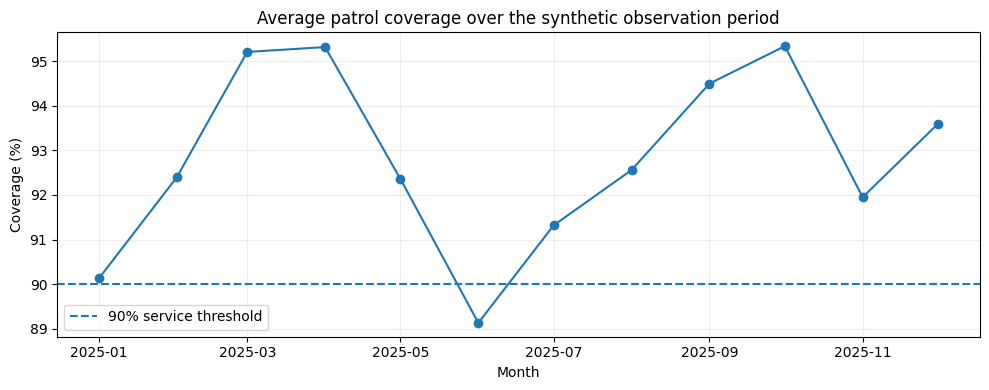

In [2]:
monthly = df.groupby('date', as_index=False)['patrol_coverage_rate'].mean()
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(monthly['date'], monthly['patrol_coverage_rate'], marker='o')
ax.axhline(90, linestyle='--', label='90% service threshold')
ax.set(title='Average patrol coverage over the synthetic observation period', xlabel='Month', ylabel='Coverage (%)')
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 3. Expanding-window out-of-sample forecasts

Layer 1 = trailing four-period average; Layer 2 = Holt linear-trend exponential smoothing; Layer 3 = Ridge regression with lagged features. A prediction for date *t* must use target values from dates strictly before *t*.

In [3]:
forecasts = expanding_window_forecasts(df)
if forecasts.empty:
    raise ValueError('No out-of-sample forecasts generated.')
forecasts['date'] = pd.to_datetime(forecasts['date'])
forecasts['train_latest_date'] = pd.to_datetime(forecasts['train_latest_date'])
assert (forecasts['train_latest_date'] < forecasts['date']).all(), 'Look-ahead bias: future training dates found!'
print(f"OOS predictions: {len(forecasts)}")
print('Training-date check: PASSED')
display(forecasts.head())

OOS predictions: 80
Training-date check: PASSED


,deployment_id,date,actual,baseline_pred,holt_pred,ridge_pred,train_latest_date,ridge_training_rows,intervention_flag
0,AIDO-001,2025-05-01,94.9,96.525,96.950000,94.420663,2025-04-01,30,False
1,AIDO-002,2025-05-01,94.5,94.200,94.150000,94.371481,2025-04-01,30,False
2,AIDO-003,2025-05-01,96.2,95.400,97.200002,94.341406,2025-04-01,30,False
3,AIDO-004,2025-05-01,69.0,95.150,94.250000,94.175837,2025-04-01,30,False
4,AIDO-005,2025-05-01,96.7,89.875,108.000000,94.080415,2025-04-01,30,False


## 4. Model performance — MAE and RMSE

,model,MAE,RMSE
0,Layer 1 - Baseline,5.793,9.877
1,Layer 2 - Holt,8.054,15.040
2,Layer 3 - Ridge,4.551,8.648


Ridge MAE improvement vs baseline: 21.44%


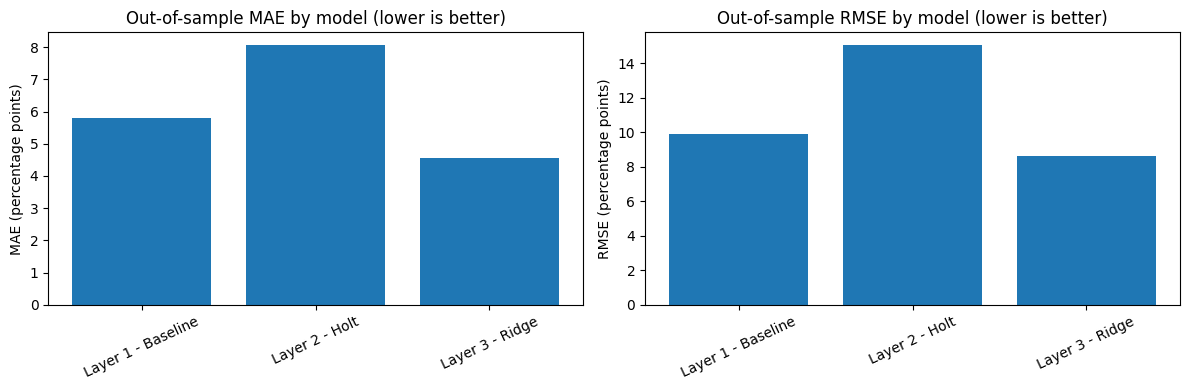

In [4]:
scores = model_metrics(forecasts)
base_mae = float(scores.loc[scores['model'].str.contains('Baseline'), 'MAE'].iloc[0])
ridge_mae = float(scores.loc[scores['model'].str.contains('Ridge'), 'MAE'].iloc[0])
improvement_pct = 100 * (base_mae - ridge_mae) / base_mae
display(scores.round(3))
print(f'Ridge MAE improvement vs baseline: {improvement_pct:.2f}%')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ['MAE', 'RMSE']):
    ax.bar(scores['model'], scores[metric])
    ax.set(title=f'Out-of-sample {metric} by model (lower is better)', ylabel=f'{metric} (percentage points)')
    ax.tick_params(axis='x', labelrotation=25)
plt.tight_layout()
plt.show()

## 5. Actual vs. predicted — one deployment

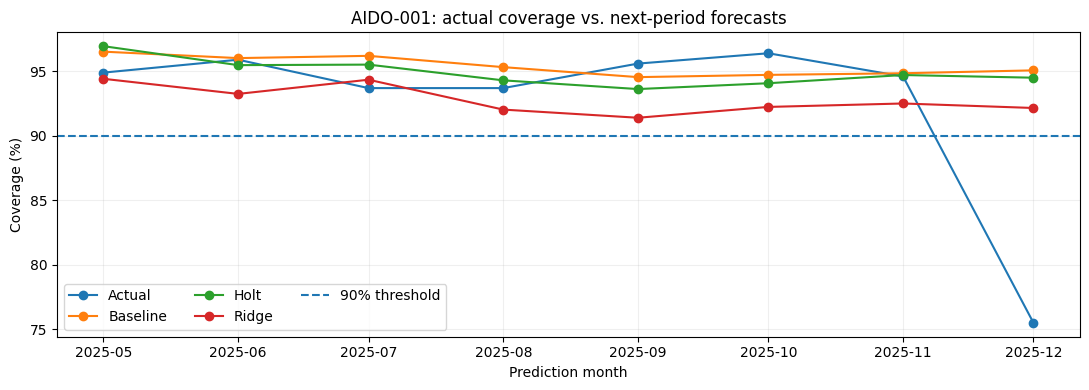

In [5]:
deployment = sorted(forecasts['deployment_id'].unique())[0]
one = forecasts.loc[forecasts['deployment_id'].eq(deployment)].sort_values('date')
fig, ax = plt.subplots(figsize=(11, 4))
for column, label in [('actual', 'Actual'), ('baseline_pred', 'Baseline'), ('holt_pred', 'Holt'), ('ridge_pred', 'Ridge')]:
    ax.plot(one['date'], one[column], marker='o', label=label)
ax.axhline(90, linestyle='--', label='90% threshold')
ax.set(title=f'{deployment}: actual coverage vs. next-period forecasts', xlabel='Prediction month', ylabel='Coverage (%)')
ax.legend(ncol=3)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 6. Operational intervention flags and missed cases

An **intervention flag** is raised if Ridge forecasts patrol coverage below 90%. A zero-flag result is not automatically good: we also count actual below-threshold observations that were missed. These comparisons are descriptive diagnostics on *synthetic* data.

In [6]:
flags = forecasts.copy()
flags['predicted_below_90'] = flags['ridge_pred'] < 90
flags['actual_below_90'] = flags['actual'] < 90
flags['missed_low_coverage'] = (~flags['predicted_below_90']) & flags['actual_below_90']
print('Predicted below 90%:', int(flags['predicted_below_90'].sum()))
print('Actual below 90%:   ', int(flags['actual_below_90'].sum()))
print('Missed low periods: ', int(flags['missed_low_coverage'].sum()))
display(flags.loc[flags['predicted_below_90'] | flags['actual_below_90'],
                  ['deployment_id', 'date', 'actual', 'ridge_pred', 'predicted_below_90', 'missed_low_coverage']].sort_values(['date','deployment_id']))

Predicted below 90%: 0
Actual below 90%:    7
Missed low periods:  7


,deployment_id,date,actual,ridge_pred,predicted_below_90,missed_low_coverage
3,AIDO-004,2025-05-01,69.0,94.175837,False,True
14,AIDO-005,2025-06-01,57.0,93.224696,False,True
19,AIDO-010,2025-06-01,71.7,94.162283,False,True
22,AIDO-003,2025-07-01,64.1,94.285264,False,True
37,AIDO-008,2025-08-01,58.3,92.700298,False,True
61,AIDO-002,2025-11-01,69.8,92.699563,False,True
70,AIDO-001,2025-12-01,75.5,92.158192,False,True


## 7. Save evaluation outputs

In [7]:
output_path = ROOT / 'data' / 'W05_Forecast_Results.csv'
forecasts.to_csv(output_path, index=False)
print(f'Saved: {output_path}')

Saved: /Users/xiaoma/Desktop/Ingen intern/week5/data/W05_Forecast_Results.csv


## 8. Interpretation and limitations

- The preferred layer is the model with the lowest observed out-of-sample MAE; also compare RMSE, especially sensitivity to large errors.
- Report any improvement against the trailing-four-period baseline, **not** against in-sample fitted values.
- A model that never flags coverage below 90% may miss meaningful operational risks. Review the missed cases above before making any maintenance recommendation.
- Training and evaluation use 12 months of **synthetic** data. Results are illustrative, not validated production performance.
- The training-date assertion is an initial sanity check, not a substitute for the required 30+ pytest tests or full feature-leakage review.
- Forecasts are intended for **one period ahead**; further horizons would require separate validation.

## Supplemental validation: Ridge coefficient stability and 90% intervention flags
The specified 20% adjacent-window coefficient-change requirement is explicitly audited. A breach is recorded rather than hidden. Precision is undefined when there are zero predicted positive alerts.

In [17]:
from src.forecasting import load_aido_data, expanding_window_forecasts, ridge_coefficient_stability, intervention_diagnostics
aido = load_aido_data()
oos = expanding_window_forecasts(aido)
audit = ridge_coefficient_stability(aido)
alert_report = intervention_diagnostics(oos)
print('Stability: comparable coefficient transitions:', audit.relative_change_pct.notna().sum())
print('Stability: >20% breaches:', int((audit.relative_change_pct > 20).sum()))
print('Stability: maximum relative change (%):', round(audit.relative_change_pct.max(), 2))
print('90% intervention performance:', alert_report)
from IPython.display import display
display(audit[['prediction_date','feature','coefficient','prior_coefficient','relative_change_pct','within_20pct']])
audit.to_csv('data/W05_Ridge_Coefficient_Stability.csv', index=False)

Stability: comparable coefficient transitions: 28
Stability: >20% breaches: 20
Stability: maximum relative change (%): 2818.09
90% intervention performance: {'threshold': 90.0, 'TP': 0, 'FP': 0, 'FN': 7, 'TN': 73, 'precision': None, 'recall': 0.0, 'specificity': 1.0}
